In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import numpy as np
path = "/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy"

data = np.load(path)
print(data.shape)


(32, 140, 73, 512)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

species_names = [
    "Aiele", "African mahogany", "Ako", "Avodire", "Azobe", "Bete", "Bosse", "Bubinga",
    "Dau", "Dibetou", "Doussie", "Framire", "Ilomba", "Iroko", "Kossipo", "Kotibe",
    "Limba", "Makore", "Niangon", "Niove", "Okoume", "Olon", "Ozigo", "Rosewood",
    "Cam Lai Rosewood", "Rosewood Trac", "Samba", "Sapelli", "Sipo", "Teck", "Tiama", "Zingana"
]

def plot_tropical_group_signals(data, group_idx, group_size=8):
    """
    Plot individual normal vs defect signals over time for 8 species
    in a tropical group, using full species names in the legend.

    Parameters:
    - data: ndarray of shape [num_samples, T, 73, F]
    - group_idx: which group (0 to 3 for 32 samples)
    - group_size: number of species per group (default 8)
    """
    start = group_idx * group_size
    end = start + group_size
    group_data = data[start:end]
    group_species = species_names[start:end]

    plt.figure(figsize=(12, 6))

    for i, (sample, species) in enumerate(zip(group_data, group_species)):

        std_map = sample.std(axis=0).mean(axis=-1)
        normal_idx = np.argmin(std_map)
        defect_idx = np.argmax(std_map)

        normal_signal = np.abs(sample[:, normal_idx, :]).mean(axis=1)
        defect_signal = np.abs(sample[:, defect_idx, :]).mean(axis=1)

        plt.plot(normal_signal, label=f"Normal - {species}", linestyle='--')
        plt.plot(defect_signal, label=f"Defect - {species}")

    plt.title(f"Tropical Group {group_idx + 1} — Temporal Signals per Species")
    plt.xlabel("Time")
    plt.ylabel("Signal Magnitude")
    plt.legend(ncol=2, fontsize=8)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


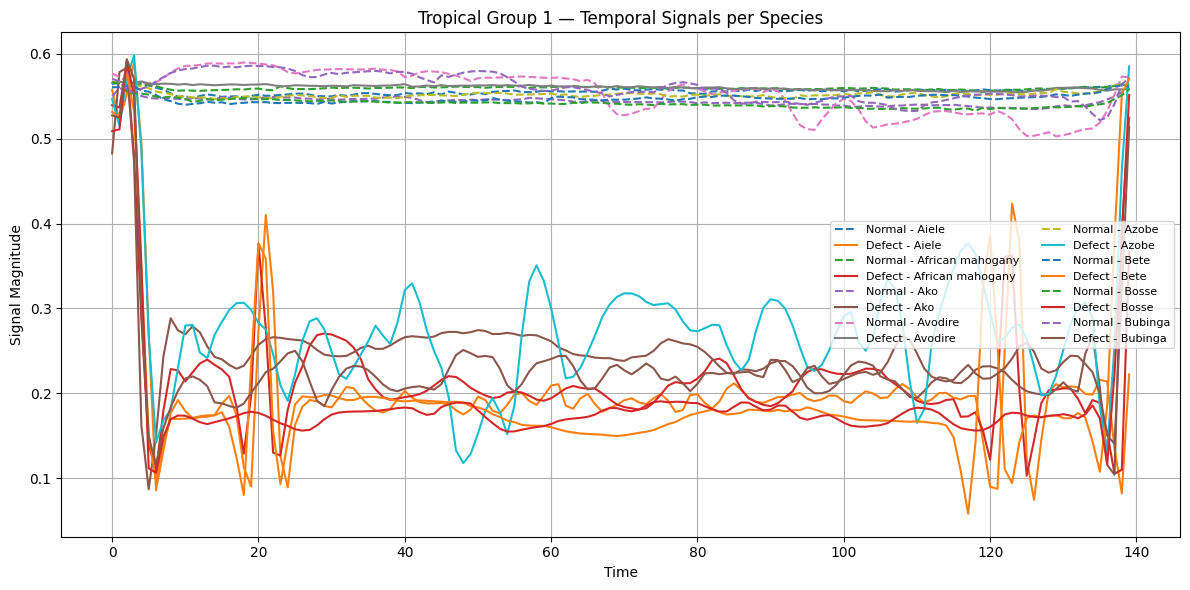

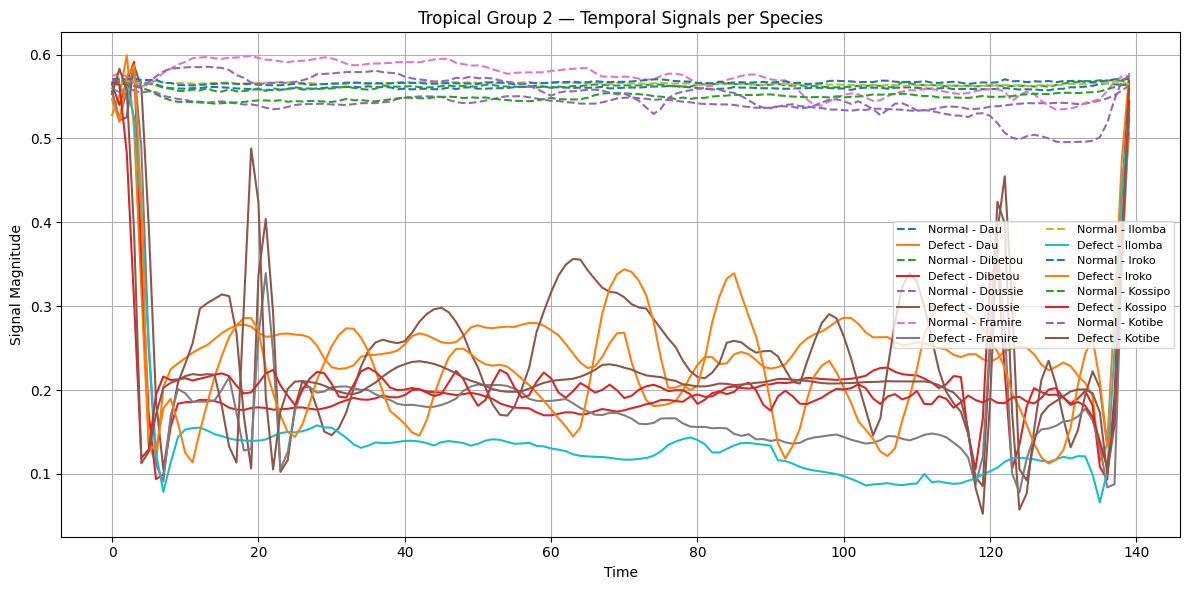

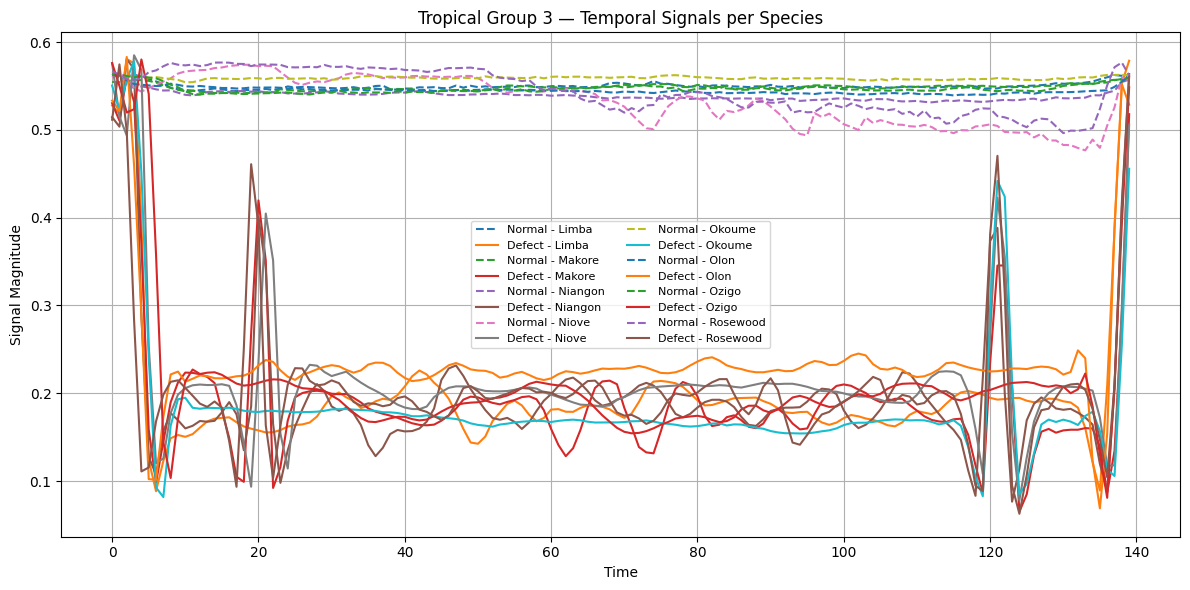

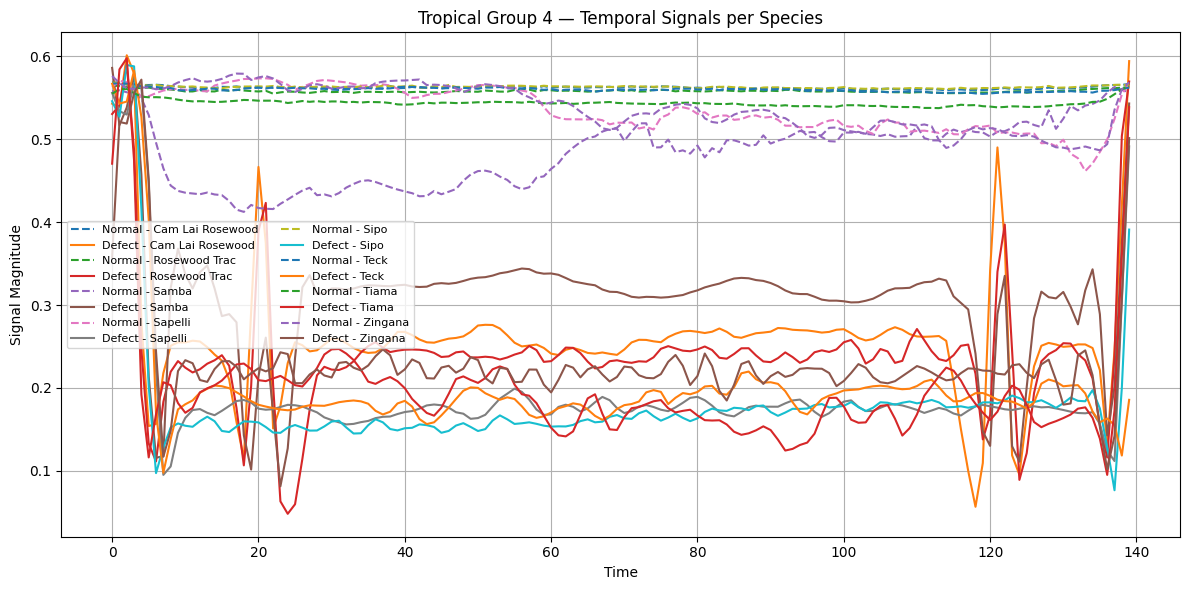

In [ ]:
plot_tropical_group_signals(data, group_idx=0)
plot_tropical_group_signals(data, group_idx=1)
plot_tropical_group_signals(data, group_idx=2)
plot_tropical_group_signals(data, group_idx=3)



[Group 1] High-STD Pixel Coordinates:
1. Pixel at (row=20, col=22) with STD = 0.3247
2. Pixel at (row=122, col=51) with STD = 0.2682
3. Pixel at (row=121, col=25) with STD = 0.2520


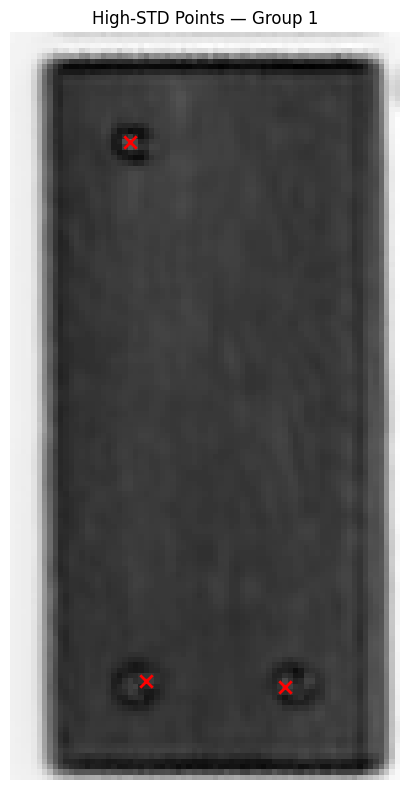


[Group 2] High-STD Pixel Coordinates:
1. Pixel at (row=121, col=51) with STD = 0.2953
2. Pixel at (row=20, col=24) with STD = 0.2921
3. Pixel at (row=121, col=21) with STD = 0.2833


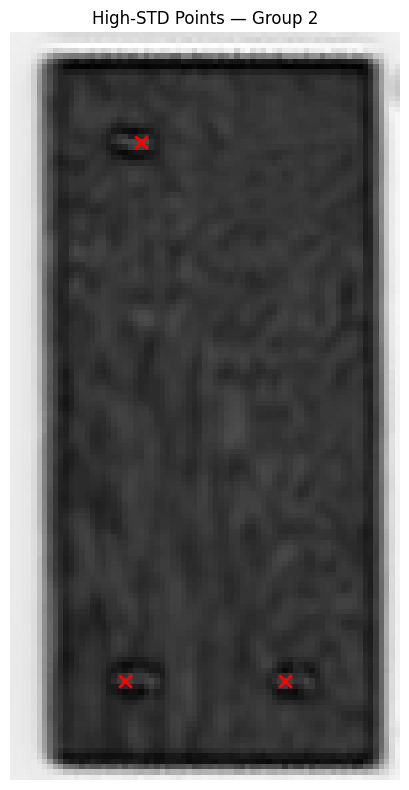


[Group 3] High-STD Pixel Coordinates:
1. Pixel at (row=121, col=53) with STD = 0.3590
2. Pixel at (row=121, col=23) with STD = 0.3269
3. Pixel at (row=21, col=21) with STD = 0.3005


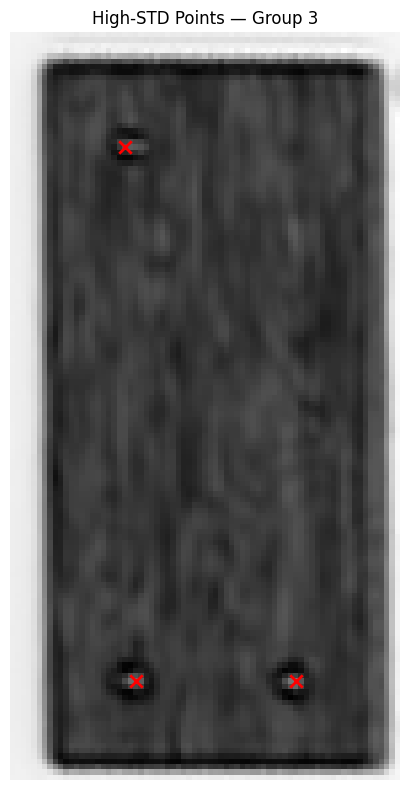


[Group 4] High-STD Pixel Coordinates:
1. Pixel at (row=121, col=23) with STD = 0.3105
2. Pixel at (row=121, col=54) with STD = 0.2903
3. Pixel at (row=19, col=25) with STD = 0.2781


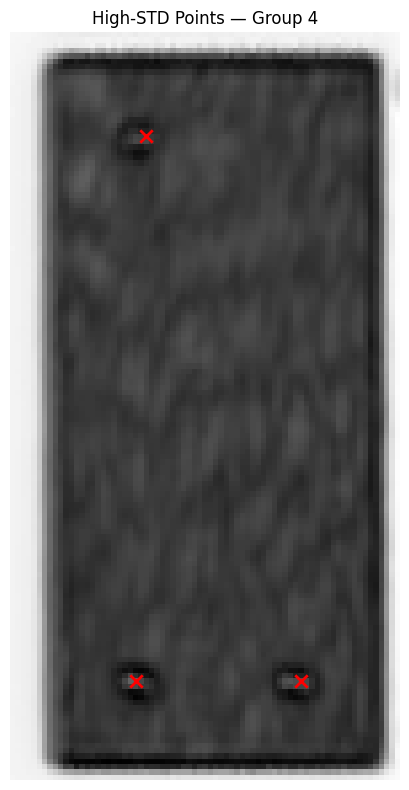


[Group 5] High-STD Pixel Coordinates:
1. Pixel at (row=20, col=22) with STD = 0.3200
2. Pixel at (row=121, col=52) with STD = 0.3154
3. Pixel at (row=121, col=22) with STD = 0.2924


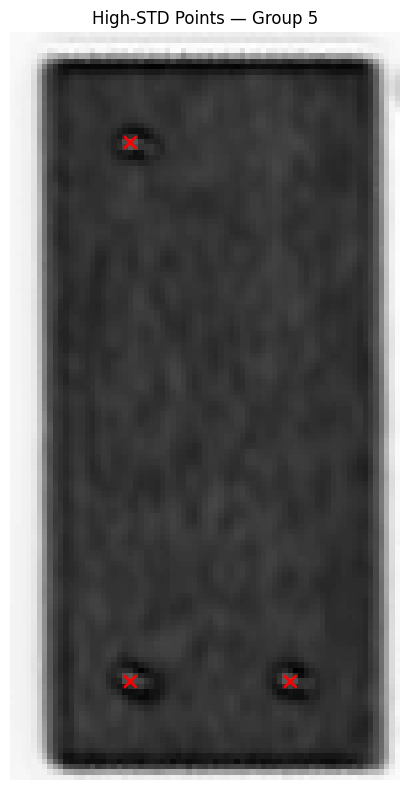


[Group 6] High-STD Pixel Coordinates:
1. Pixel at (row=121, col=23) with STD = 0.3431
2. Pixel at (row=121, col=53) with STD = 0.3260
3. Pixel at (row=20, col=23) with STD = 0.2685


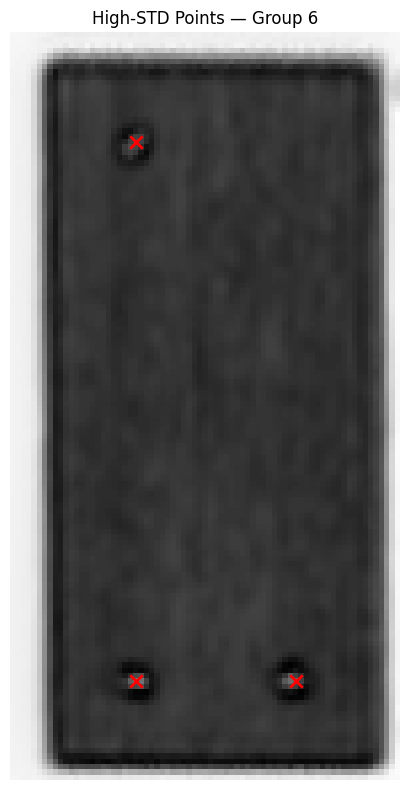


[Group 7] High-STD Pixel Coordinates:
1. Pixel at (row=121, col=52) with STD = 0.3302
2. Pixel at (row=21, col=23) with STD = 0.3239
3. Pixel at (row=21, col=53) with STD = 0.3185


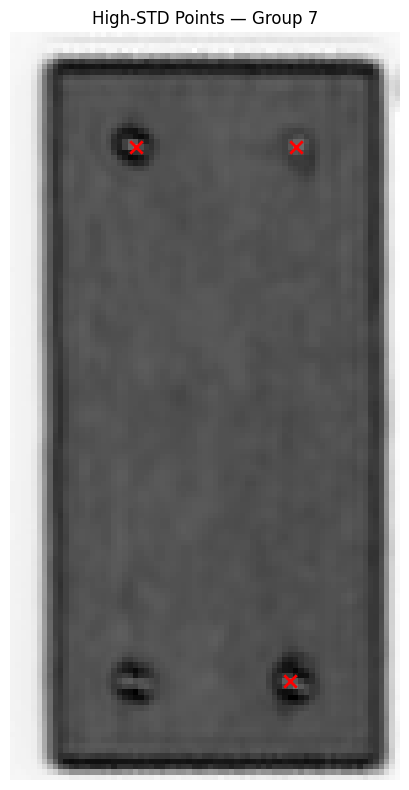


[Group 8] High-STD Pixel Coordinates:
1. Pixel at (row=123, col=26) with STD = 0.3310
2. Pixel at (row=21, col=25) with STD = 0.2996
3. Pixel at (row=122, col=54) with STD = 0.2693


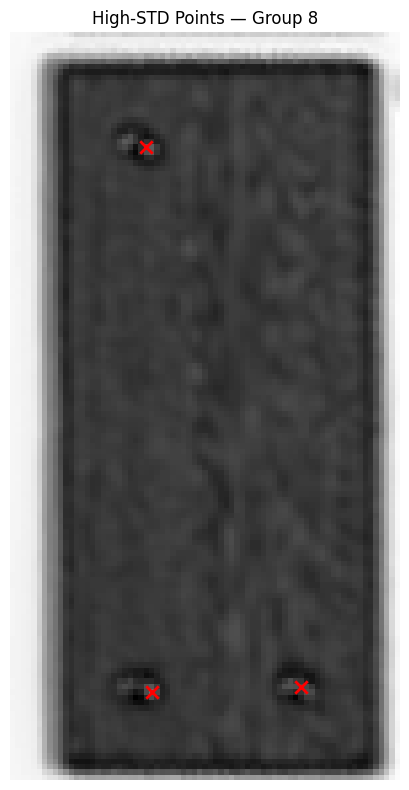

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

data = np.load("/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy")

species_names = [
    "Aiele", "African mahogany", "Ako", "Avodire", "Azobe", "Bete", "Bosse", "Bubinga",
    "Dau", "Dibetou", "Doussie", "Framire", "Ilomba", "Iroko", "Kossipo", "Kotibe",
    "Limba", "Makore", "Niangon", "Niove", "Okoume", "Olon", "Ozigo", "Rosewood",
    "Cam Lai Rosewood", "Rosewood Trac", "Samba", "Sapelli", "Sipo", "Teck", "Tiama", "Zingana"
]

tropical_groups = {
    "Group 1": ["Aiele", "African mahogany", "Ako", "Avodire"],
    "Group 2": ["Azobe", "Bete", "Bosse", "Bubinga"],
    "Group 3": ["Dau", "Dibetou", "Doussie", "Framire"],
    "Group 4": ["Ilomba", "Iroko", "Kossipo", "Kotibe"],
    "Group 5": ["Limba", "Makore", "Niangon", "Niove"],
    "Group 6": ["Okoume", "Olon", "Ozigo", "Rosewood"],
    "Group 7": ["Cam Lai Rosewood", "Rosewood Trac", "Samba", "Sapelli"],
    "Group 8": ["Sipo", "Teck", "Tiama", "Zingana"],
}

border = 10
num_points = 3
min_dist = 20
H, W = data.shape[1:3]
valid_mask = np.zeros((H, W), dtype=bool)
valid_mask[border:H-border, border:W-border] = True

species_to_index = {name.lower(): idx for idx, name in enumerate(species_names)}

for group_name, group_species in tropical_groups.items():
    indices = [species_to_index[sp.lower()] for sp in group_species if sp.lower() in species_to_index]
    if not indices:
        print(f"\n{group_name}: No matching samples.")
        continue

    group_data = data[indices]
    temporal_std = np.std(group_data, axis=(0, -1))

    masked_std = np.where(valid_mask, temporal_std, -np.inf)
    flat_indices = np.argsort(masked_std.ravel())[::-1]
    coords = np.column_stack(np.unravel_index(flat_indices, (H, W)))


    selected = []
    for (r, c) in coords:
        if len(selected) == 0:
            selected.append((r, c))
        else:
            dist = cdist([(r, c)], selected)
            if np.min(dist) >= min_dist:
                selected.append((r, c))
        if len(selected) == num_points:
            break


    print(f"\n[{group_name}] High-STD Pixel Coordinates:")
    for idx, (r, c) in enumerate(selected, 1):
        print(f"{idx}. Pixel at (row={r}, col={c}) with STD = {temporal_std[r, c]:.4f}")


    energy_map = np.sum(np.abs(group_data), axis=(0, 3)) / len(indices)

    plt.figure(figsize=(6, 8))
    plt.imshow(energy_map, cmap='gray')
    for (r, c) in selected:
        plt.scatter(c, r, c='red', s=80, marker='x', linewidths=2)
    plt.title(f"High-STD Points — {group_name}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()


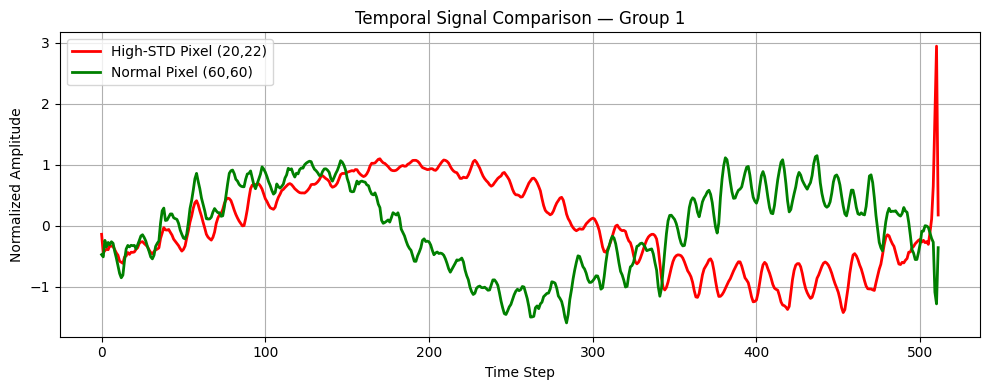

/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


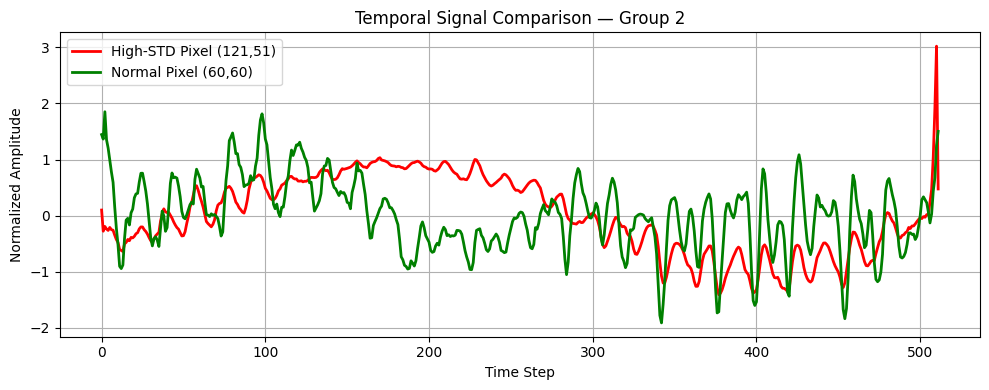

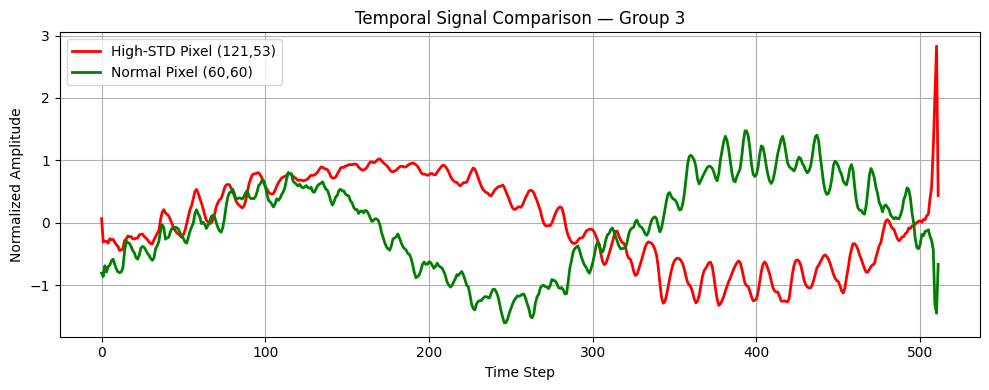

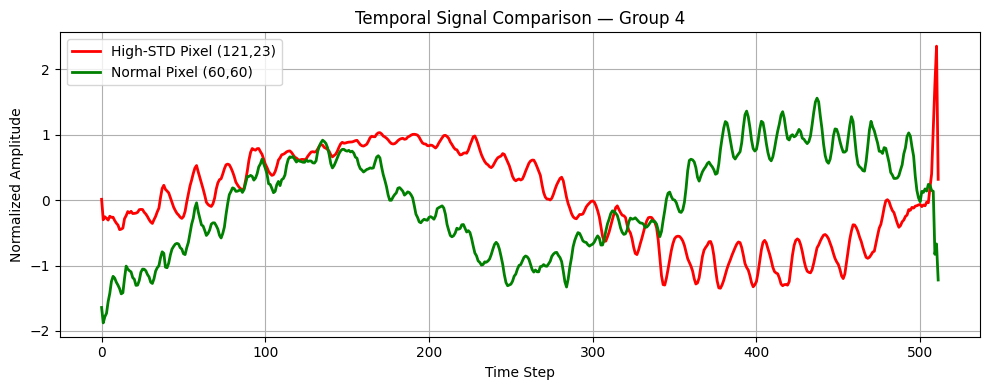

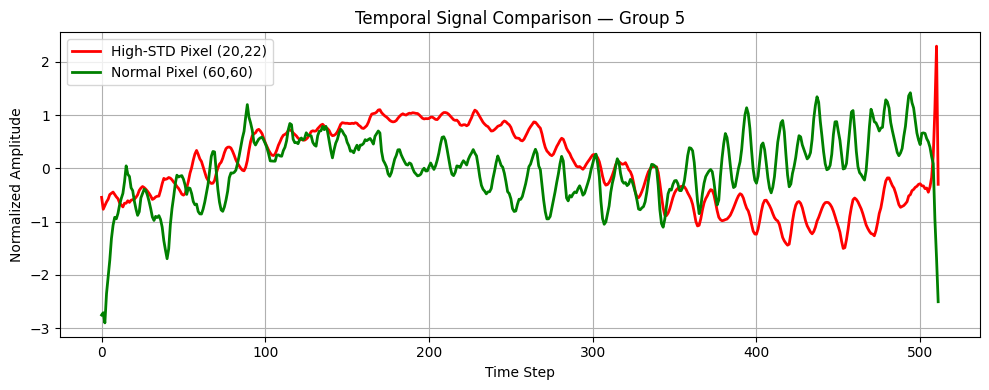

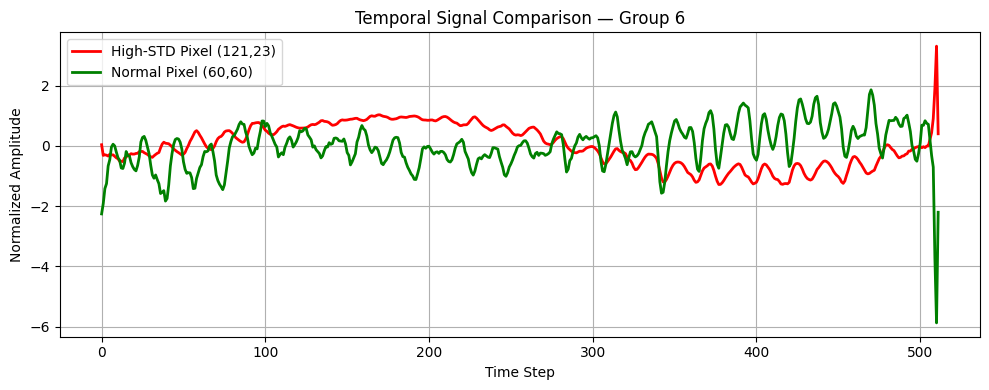

/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


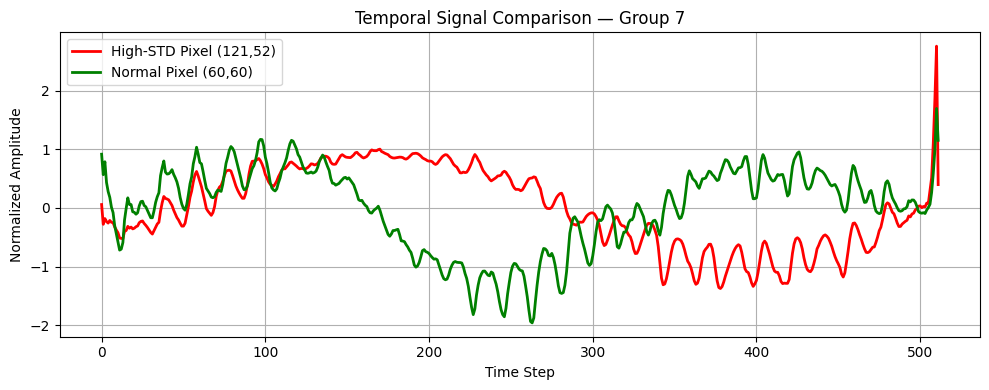

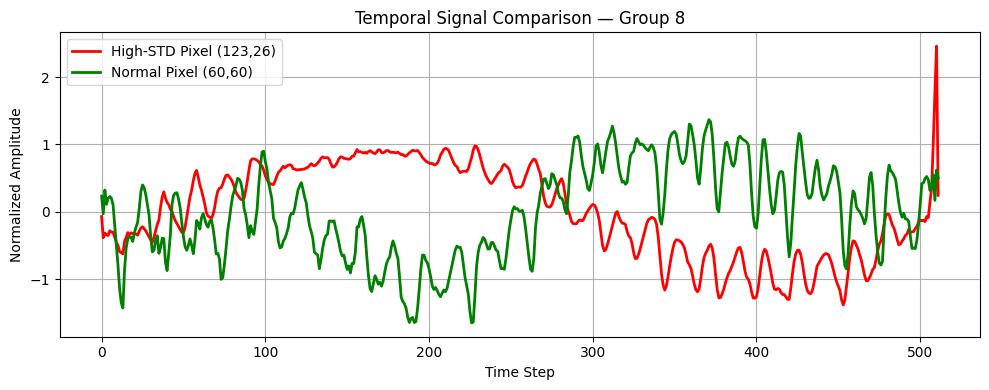

In [ ]:
species_names = [
    "Aiele", "African mahogany", "Ako", "Avodire", "Azobe", "Bete", "Bosse", "Bubinga",
    "Dau", "Dibetou", "Doussie", "Framire", "Ilomba", "Iroko", "Kossipo", "Kotibe",
    "Limba", "Makore", "Niangon", "Niove", "Okoume", "Olon", "Ozigo", "Rosewood",
    "Cam Lai Rosewood", "Rosewood Trac", "Samba", "Sapelli", "Sipo", "Teck", "Tiama", "Zingana"
]

tropical_groups = {
    "Group 1": ["Aiele", "African mahogany", "Ako", "Avodire"],
    "Group 2": ["Azobe", "Bete", "Bosse", "Bubinga"],
    "Group 3": ["Dau", "Dibetou", "Doussie", "Framire"],
    "Group 4": ["Ilomba", "Iroko", "Kossipo", "Kotibe"],
    "Group 5": ["Limba", "Makore", "Niangon", "Niove"],
    "Group 6": ["Okoume", "Olon", "Ozigo", "Rosewood"],
    "Group 7": ["Cam Lai Rosewood", "Rosewood Trac", "Samba", "Sapelli"],
    "Group 8": ["Sipo", "Teck", "Tiama", "Zingana"],
}


high_std_pixels = {
    "Group 1": (20, 22),
    "Group 2": (121, 51),
    "Group 3": (121, 53),
    "Group 4": (121, 23),
    "Group 5": (20, 22),
    "Group 6": (121, 23),
    "Group 7": (121, 52),
    "Group 8": (123, 26),
}


def normalize(signal):
    return (signal - np.mean(signal)) / (np.std(signal) + 1e-6)


species_to_index = {name.lower(): i for i, name in enumerate(species_names)}


for group_name, species_list in tropical_groups.items():
    sample_indices = [species_to_index[s.lower()] for s in species_list if s.lower() in species_to_index]
    group_data = data[sample_indices]


    r1, c1 = high_std_pixels[group_name]
    high_signal = group_data[:, r1, c1, :].mean(axis=0)
    high_signal = normalize(high_signal)


    r2, c2 = 60, 60
    normal_signal = group_data[:, r2, c2, :].mean(axis=0)
    normal_signal = normalize(normal_signal)



    plt.figure(figsize=(10, 4))
    plt.plot(high_signal, label=f"High-STD Pixel ({r1},{c1})", color='red', linewidth=2)
    plt.plot(normal_signal, label=f"Normal Pixel ({r2},{c2})", color='green', linewidth=2)
    plt.xlabel("Time Step")
    plt.ylabel("Normalized Amplitude")
    plt.title(f"Temporal Signal Comparison — {group_name}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


thz_path = "/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy"
thz_data = np.load(thz_path, mmap_mode='r')


num_samples = 32
border = 10
center_exclude_size = 50
top_n = 50
compare_signals = True


def normalize(signal):
    mag = np.abs(signal)
    return (mag - np.mean(mag)) / (np.std(mag) + 1e-6)

for sample in range(num_samples):
    thz_sample = thz_data[sample]
    height, width, _ = thz_sample.shape

    center_i, center_j = height // 2, width // 2
    scores = []
    coords = []

    for i in range(border, height - border):
        for j in range(border, width - border):
            if abs(i - center_i) < center_exclude_size // 2 and abs(j - center_j) < center_exclude_size // 2:
                continue

            signal = normalize(thz_sample[i, j, :])
            peak = np.max(signal)
            jump1 = signal[10] - signal[9]
            jump2 = signal[20] - signal[19]
            diff_sum = np.sum(np.abs(np.diff(signal)))

            score = 0.5 * peak + 0.2 * jump1 + 0.2 * jump2 + 0.1 * (diff_sum / len(signal))
            scores.append(score)
            coords.append((i, j))


    top_idx = np.argsort(scores)[-top_n:]
    top_coords = [coords[i] for i in top_idx]


    plt.figure(figsize=(6, 8))
    energy_map = np.sum(np.abs(thz_sample), axis=2)
    plt.imshow(energy_map, cmap='gray')
    for i, j in top_coords:
        plt.scatter(j, i, c='red', s=25, edgecolors='black', marker='o')
    plt.title(f"Hole Detection on Sample {sample}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()


    if compare_signals:
        best = top_coords[-1]
        worst = coords[np.argsort(scores)[0]]
        best_signal = normalize(thz_sample[best[0], best[1], :])
        worst_signal = normalize(thz_sample[worst[0], worst[1], :])

        plt.figure(figsize=(10, 4))
        plt.plot(best_signal, label=f"Hole Signal at {best}", color='red')
        plt.plot(worst_signal, label=f"Non-Hole Signal at {worst}", color='green')
        plt.xlabel("Time Step")
        plt.ylabel("Normalized Amplitude")
        plt.title(f"Temporal Signal Comparison (Sample {sample})")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.9 MB/s eta 0:00:00


/tmp/ipython-input-3-3721710761.py:27: UserWarning: Input data is complex, switching to return_onesided=False
  f, t, Zxx = stft(signal, nperseg=16)


R^2: -1.5197972884270468
MAE: 217.41453221602634


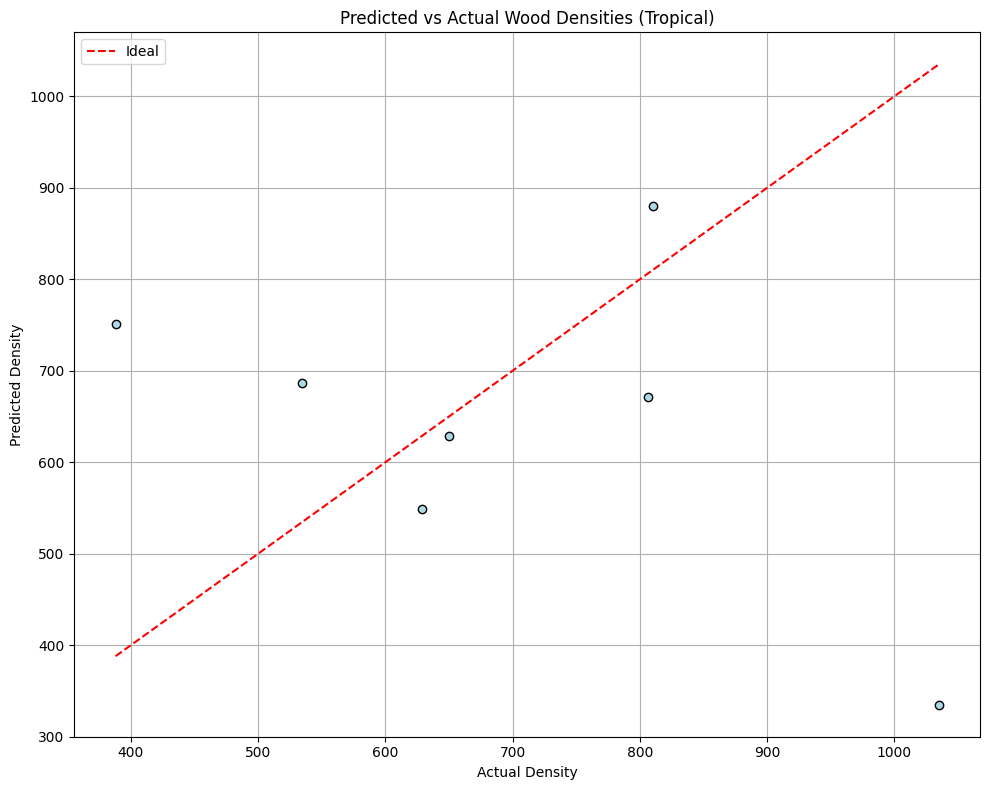

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.stats import skew, kurtosis
from scipy.signal import stft
from xgboost import XGBRegressor


npy_path = '/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy'
data_complex = np.load(npy_path, mmap_mode='r')

df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
df["Species"] = df["Species"].str.strip().str.lower()
density_col = [col for col in df.columns if 'density' in col.lower()][0]
species_density = dict(zip(df["Species"], df[density_col]))
species_labels = df["Species"].tolist()


def extract_features(signal):
    mag = np.abs(signal)
    phase = np.angle(signal)
    fft_mag = np.abs(np.fft.fft(signal))[:len(signal)//2]
    grad = np.abs(np.diff(mag)).mean()
    f, t, Zxx = stft(signal, nperseg=16)
    stft_mag = np.abs(Zxx)

    def signal_entropy(x):
        p = np.abs(x)**2
        p /= p.sum() + 1e-10
        return -np.sum(p * np.log2(p + 1e-10))

    hf_ratio = np.sum(fft_mag[len(fft_mag)//2:]) / (np.sum(fft_mag) + 1e-10)
    zcr = ((np.diff(np.sign(mag)) != 0).sum()) / len(mag)

    return [
        mag.mean(), mag.std(), np.max(mag), np.min(mag), np.median(mag),
        skew(mag), kurtosis(mag),
        phase.mean(), phase.std(), np.median(phase),
        np.mean(fft_mag), np.std(fft_mag), np.max(fft_mag),
        grad, signal_entropy(fft_mag), np.argmax(fft_mag), hf_ratio, zcr,
        np.mean(stft_mag), np.std(stft_mag), np.max(stft_mag),
        np.mean(np.sum(stft_mag, axis=0))
    ]

X, y = [], []
for i, species in enumerate(species_labels):
    dens = species_density.get(species)
    if dens is None:
        continue
    sample = data_complex[i]
    std_map = np.std(np.abs(sample), axis=0)
    coords = np.unravel_index(np.argsort(-std_map.ravel())[:10], std_map.shape)
    feats = [extract_features(sample[:, r, c]) for r, c in zip(*coords)]
    X.append(np.mean(feats, axis=0))
    y.append(dens)

X = StandardScaler().fit_transform(X)
y_log = np.log1p(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_log, test_size=0.2, random_state=42)

model = XGBRegressor(objective='reg:squarederror', n_estimators=300, learning_rate=0.05, max_depth=5)
model.fit(X_train, y_train)

y_pred_log = model.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)

print("R^2:", r2_score(y_true, y_pred))
print("MAE:", mean_absolute_error(y_true, y_pred))

plt.figure(figsize=(10, 8))
plt.scatter(y_true, y_pred, c='lightblue', edgecolors='k')
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', label='Ideal')
plt.xlabel("Actual Density")
plt.ylabel("Predicted Density")
plt.title("Predicted vs Actual Wood Densities (Tropical)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

data_real = np.load('/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy')

df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')


In [ ]:
MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)


In [ ]:
df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000


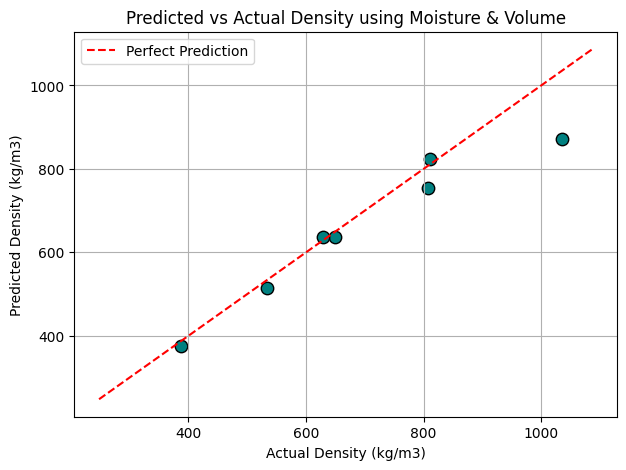

R² Score: 0.8849873514259089
Mean Absolute Error: 40.938144006869926


In [ ]:
features = ["Mass (g)", "Volume_cm3", "MC_t"]
target = "Density (kg/m3)"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)


y_pred = model.predict(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='teal', edgecolor='k', s=80)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Perfect Prediction')
plt.xlabel('Actual Density (kg/m3)')
plt.ylabel('Predicted Density (kg/m3)')
plt.title('Predicted vs Actual Density using Moisture & Volume')
plt.legend()
plt.grid(True)
plt.show()


print("R² Score:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

In [ ]:

results_df = X_test.copy()
results_df["Actual Density"] = y_test.values
results_df["Predicted Density"] = y_pred
results_df["Absolute Error"] = np.abs(results_df["Actual Density"] - results_df["Predicted Density"])

results_df = results_df.merge(df[["Mass (g)", "Species"]], on="Mass (g)", how="left")

results_df = results_df[["Species", "Actual Density", "Predicted Density", "Absolute Error"]]

results_df = results_df.sort_values("Absolute Error", ascending=False)

pd.set_option("display.max_rows", 40)
print(results_df.to_string(index=False))


         Species  Actual Density  Predicted Density  Absolute Error
Cam Lai Rosewood     1035.041458         870.887692      164.153765
          Kotibe      806.714645         753.353964       53.360680
           Tiama      534.253213         514.735071       19.518142
             Dau      810.638310         824.887958       14.249647
            Teck      649.927307         635.810001       14.117305
         Dibetou      387.984006         374.415800       13.568206
          Makore      628.892582         636.491844        7.599262


Cross-Validated R² Score: 0.8568
Cross-Validated Mean Absolute Error: 40.62 kg/m³


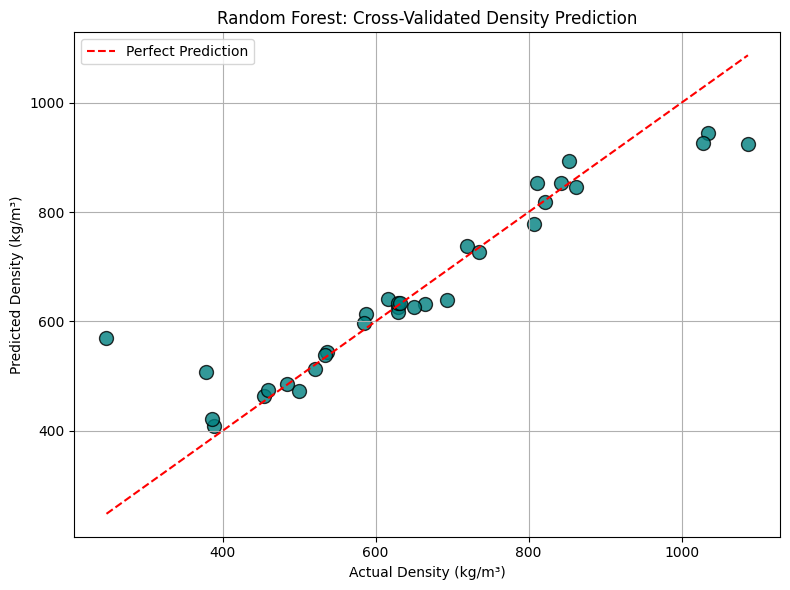

         Species  Actual Density  Predicted Density  Absolute Error
           Samba      247.909435         569.586831      321.677396
           Azobe     1086.869212         924.693464      162.175748
             Ako      377.862532         507.690465      129.827933
   Rosewood Trac     1028.750137         925.910397      102.839740
Cam Lai Rosewood     1035.041458         945.449569       89.591889
           Limba      693.283431         639.440517       53.842914
             Dau      810.638310         854.028258       43.389947
         Doussie      853.088685         893.041140       39.952455
          Ilomba      386.374906         421.727339       35.352433
         Sapelli      663.958793         632.213548       31.745244
          Kotibe      806.714645         778.679533       28.035111
           Aiele      499.489822         472.102111       27.387710
         Avodire      587.412497         613.748866       26.336369
           Iroko      616.724467         641.096

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.fft import fft

df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy')  # [32, T, H, W, F]

MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)
df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000

df["THz_mean"] = [np.abs(data_real[i]).mean() for i in range(len(df))]
df["THz_std"] = [np.abs(data_real[i]).std() for i in range(len(df))]

features = ["Mass (g)", "Volume_cm3", "MC_t", "THz_mean", "THz_std"]
X = df[features].values
y = df["Density (kg/m3)"].values

model = RandomForestRegressor(random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
y_pred = cross_val_predict(model, X, y, cv=cv)

r2 = r2_score(y, y_pred)
mae = mean_absolute_error(y, y_pred)
print(f"Cross-Validated R² Score: {r2:.4f}")
print(f"Cross-Validated Mean Absolute Error: {mae:.2f} kg/m³")

plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, c='teal', s=100, edgecolors='k', alpha=0.8)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label="Perfect Prediction")
plt.xlabel("Actual Density (kg/m³)")
plt.ylabel("Predicted Density (kg/m³)")
plt.title("Random Forest: Cross-Validated Density Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

df_result = df[["Species"]].copy()
df_result["Actual Density"] = y
df_result["Predicted Density"] = y_pred
df_result["Absolute Error"] = np.abs(df_result["Actual Density"] - df_result["Predicted Density"])
df_result = df_result.sort_values("Absolute Error", ascending=False)
print(df_result.to_string(index=False))


In [ ]:
!pip install xgboost lightgbm -q


In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy')

df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000

MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)

thz_means, thz_stds = [], []
for i in range(data_real.shape[0]):
    signal = np.abs(data_real[i])
    thz_means.append(signal.mean())
    thz_stds.append(signal.std())

df["THz_mean"] = thz_means
df["THz_std"] = thz_stds


features = ["Mass (g)", "Volume_cm3", "MC_t", "THz_mean", "THz_std"]
X = df[features]
y = df["Density (kg/m3)"]

models = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42, verbosity=0),
    "LightGBM": LGBMRegressor(random_state=42, device='cpu')
}

plt.figure(figsize=(18, 5))


for i, (name, model) in enumerate(models.items(), 1):
    model.fit(X, y)
    y_pred = model.predict(X)
    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)

    plt.subplot(1, 3, i)
    plt.scatter(y, y_pred, s=90, edgecolor='k', alpha=0.85)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
    plt.title(f"{name}\nR²: {r2:.3f} | MAE: {mae:.2f}")
    plt.xlabel("Actual Density")
    plt.ylabel("Predicted Density")
    plt.grid(True)

plt.suptitle("Model Comparison: Actual vs Predicted Density", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


AttributeError: partially initialized module 'cupy' has no attribute '_util' (most likely due to a circular import)

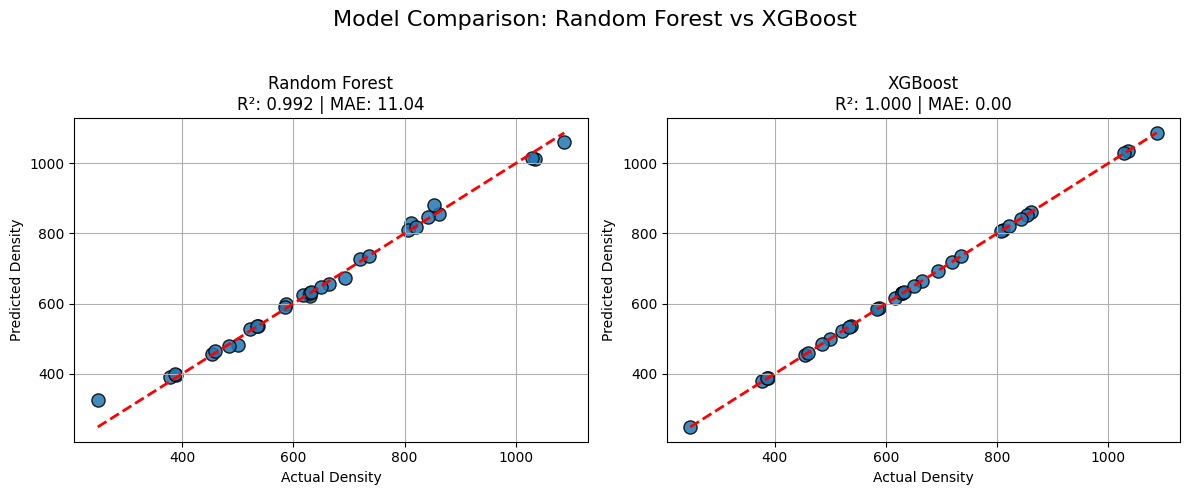

In [ ]:
# --- Install if not already ---
!pip install xgboost -q

# --- Imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor


df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy')


df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000


MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)


thz_means, thz_stds = [], []
for i in range(data_real.shape[0]):
    signal = np.abs(data_real[i])
    thz_means.append(signal.mean())
    thz_stds.append(signal.std())

df["THz_mean"] = thz_means
df["THz_std"] = thz_stds

features = ["Mass (g)", "Volume_cm3", "MC_t", "THz_mean", "THz_std"]
X = df[features]
y = df["Density (kg/m3)"]

models = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42, verbosity=0)
}

plt.figure(figsize=(12, 5))

for i, (name, model) in enumerate(models.items(), 1):
    model.fit(X, y)
    y_pred = model.predict(X)
    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)

    plt.subplot(1, 2, i)
    plt.scatter(y, y_pred, s=90, edgecolor='k', alpha=0.85)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
    plt.title(f"{name}\nR²: {r2:.3f} | MAE: {mae:.2f}")
    plt.xlabel("Actual Density")
    plt.ylabel("Predicted Density")
    plt.grid(True)

plt.suptitle("Model Comparison: Random Forest vs XGBoost", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


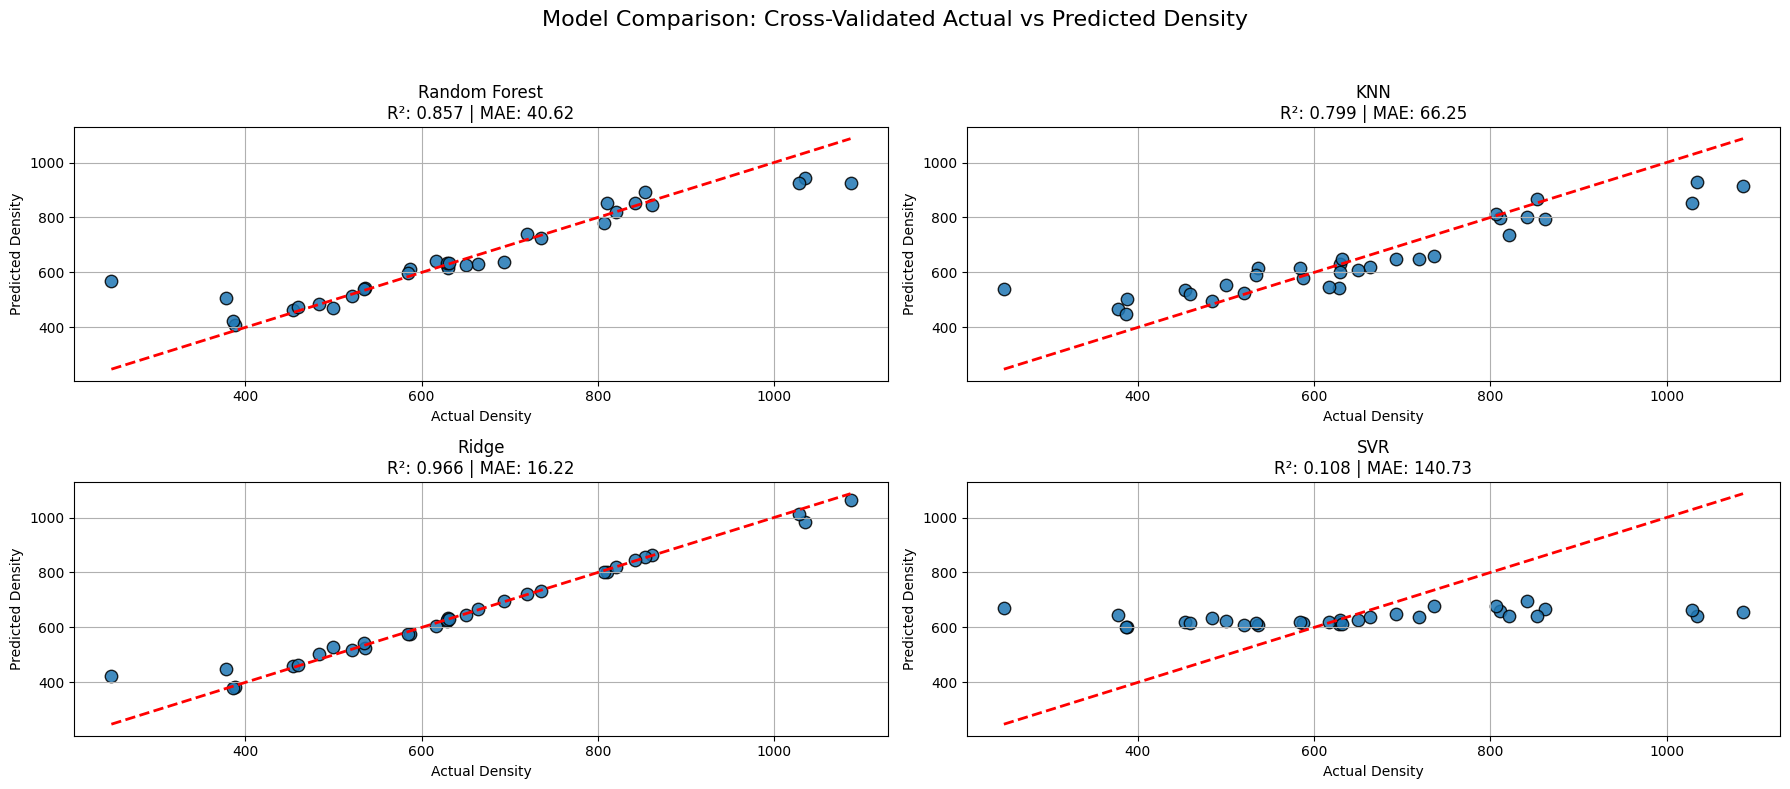

In [ ]:

!pip install scikit-learn -q


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_predict, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy')

df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000

MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)

thz_means, thz_stds = [], []
for i in range(data_real.shape[0]):
    signal = np.abs(data_real[i])
    thz_means.append(signal.mean())
    thz_stds.append(signal.std())

df["THz_mean"] = thz_means
df["THz_std"] = thz_stds

features = ["Mass (g)", "Volume_cm3", "MC_t", "THz_mean", "THz_std"]
X = df[features].values
y = df["Density (kg/m3)"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

models = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=3),
    "Ridge": Ridge(alpha=1.0),
    "SVR": SVR(kernel='rbf', C=10, epsilon=0.1)
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

plt.figure(figsize=(18, 8))
for i, (name, model) in enumerate(models.items(), 1):
    if name == "Random Forest":
        X_input = X
    else:
        X_input = X_scaled


    y_pred = cross_val_predict(model, X_input, y, cv=kf)
    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)


    plt.subplot(2, 2, i)
    plt.scatter(y, y_pred, s=80, edgecolor='k', alpha=0.85)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
    plt.title(f"{name}\nR²: {r2:.3f} | MAE: {mae:.2f}")
    plt.xlabel("Actual Density")
    plt.ylabel("Predicted Density")
    plt.grid(True)

plt.suptitle("Model Comparison: Cross-Validated Actual vs Predicted Density", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
R² Score: 0.9985
Mean Absolute Error: 4.74 kg/m³


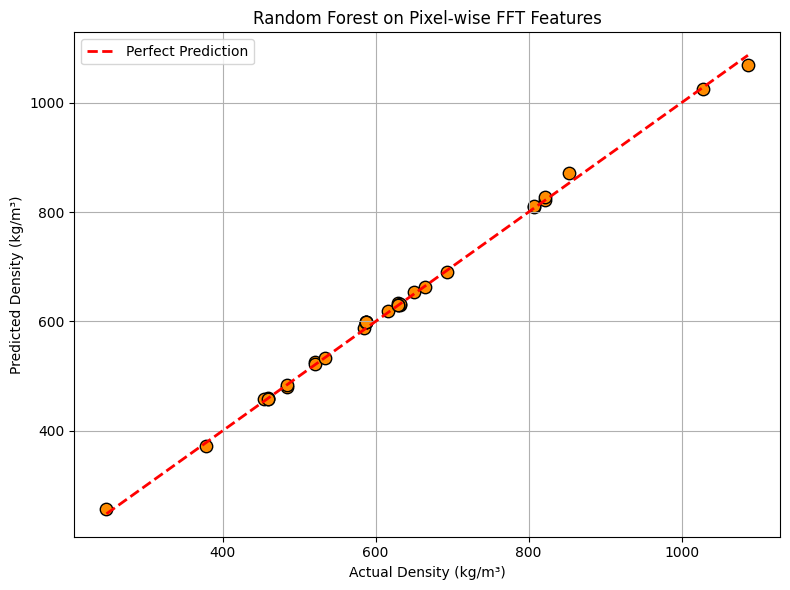

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy')

df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000
MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)

samples = []
labels = []

for i in range(data_real.shape[0]):
    signal = np.abs(data_real[i])
    T, H, W = signal.shape
    temporal_std = signal.std(axis=0)
    flat_std = temporal_std.reshape(-1)
    top_idxs = np.argsort(flat_std)[-5:]

    mass = df.loc[i, "Mass (g)"]
    volume = df.loc[i, "Volume_cm3"]
    mc_t = df.loc[i, "MC_t"]
    density = df.loc[i, "Density (kg/m3)"]

    for idx in top_idxs:

        h = idx // W
        w = idx % W

        pixel_signal = signal[:, h, w]

        spectrum = np.abs(fft(pixel_signal))[:len(pixel_signal)//2]
        features = [
            mass, volume, mc_t,
            pixel_signal.mean(),
            pixel_signal.std(),
            spectrum.mean(),
            spectrum.max()
        ]
        samples.append(features)
        labels.append(density)

X = pd.DataFrame(samples, columns=[
    "Mass", "Volume", "MC_t",
    "Pixel_Mean", "Pixel_Std",
    "FFT_Mean", "FFT_Peak"
])
y = np.array(labels)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}
grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print("Best Hyperparameters:", grid.best_params_)
print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error: {mae:.2f} kg/m³")

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='darkorange', edgecolor='k', s=80)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel("Actual Density (kg/m³)")
plt.ylabel("Predicted Density (kg/m³)")
plt.title("Random Forest on Pixel-wise FFT Features")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

results_list = []
test_indices = X_test.index

for idx in test_indices:
    species = df.loc[idx // 5, "Species"]
    actual_density = y_test[X_test.index.get_loc(idx)]
    predicted_density = y_pred[X_test.index.get_loc(idx)]


    results_list.append({
        "Species": species,
        "Actual Density": actual_density,
        "Predicted Density": predicted_density,
        "Absolute Error": np.abs(actual_density - predicted_density)
    })

results_df = pd.DataFrame(results_list)

results_df = results_df.sort_values("Absolute Error", ascending=False)

pd.set_option("display.max_rows", None)
print(results_df.to_string(index=False))

         Species  Actual Density  Predicted Density  Absolute Error
         Doussie      853.088685         871.190070       18.101385
           Azobe     1086.869212        1068.866670       18.002542
         Avodire      587.412497         599.126556       11.714060
         Avodire      587.412497         598.848145       11.435648
         Avodire      587.412497         598.640075       11.227578
         Avodire      587.412497         598.526986       11.114490
           Samba      247.909435         256.047115        8.137681
           Niove      821.054927         828.270113        7.215187
             Ako      377.862532         371.964011        5.898521
            Bete      628.803520         633.724347        4.920828
          Kotibe      806.714645         811.521410        4.806765
            Olon      521.029651         525.164443        4.134792
            Teck      649.927307         653.820661        3.893355
         Niangon      584.261186         588.139

In [ ]:
import time

start_train = time.time()
grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)
end_train = time.time()

train_time = end_train - start_train

best_model = grid.best_estimator_

start_test = time.time()
y_pred = best_model.predict(X_test)
end_test = time.time()

test_time = end_test - start_test


print("Best Hyperparameters:", grid.best_params_)

print(f"Training Time: {train_time:.2f} seconds")
print(f"Testing Time: {test_time:.4f} seconds")


Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Training Time: 5.52 seconds
Testing Time: 0.0127 seconds


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error

y_pred_train = best_model.predict(X_train)
y_pred_test = best_model.predict(X_test)


print(f"Train R²: {r2_score(y_train, y_pred_train):.4f}")
print(f"Train MAE: {mean_absolute_error(y_train, y_pred_train):.2f} kg/m³")
print(f"Test R²: {r2_score(y_test, y_pred_test):.4f}")
print(f"Test MAE: {mean_absolute_error(y_test, y_pred_test):.2f} kg/m³")


Train R²: 0.9997
Train MAE: 2.19 kg/m³
Test R²: 0.9985
Test MAE: 4.74 kg/m³


evaluation

LOSO Evaluation: 100%|██████████| 32/32 [02:08<00:00,  4.00s/it]


 LOSO with GridSearch:
R² Score: 0.8714
MAE: 42.42 kg/m³


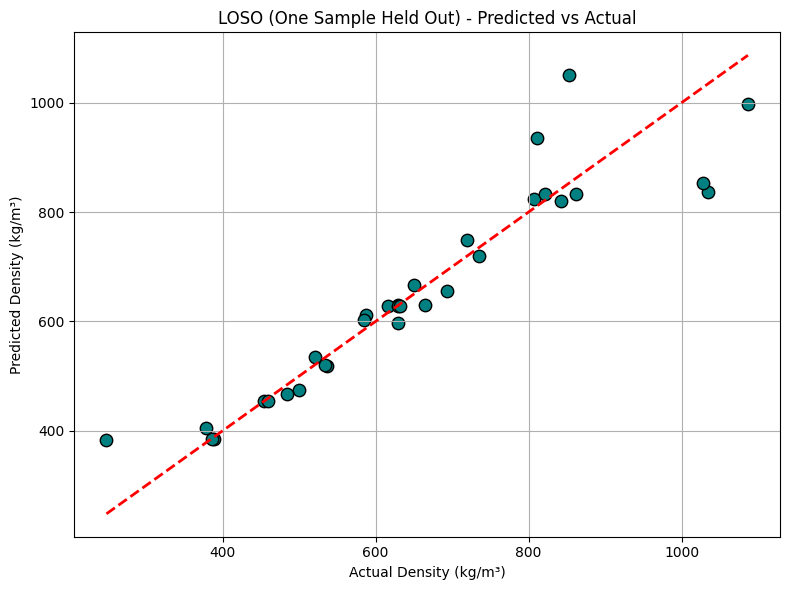

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft2
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
from tqdm import tqdm


df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')

data_real = np.load('/content/drive/MyDrive/wood data/wood/Thz/Copy of Tropical_THz.npy')
df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000
MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)

samples = []
labels = []

for i in range(data_real.shape[0]):

    image = np.abs(data_real[i]).mean(axis=0)
    H, W = image.shape
    image_flat = image.reshape(-1)

    top_idxs = np.argsort(np.abs(image_flat - image_flat.mean()))[-5:]

    mass = df.loc[i, "Mass (g)"]
    volume = df.loc[i, "Volume_cm3"]
    mc_t = df.loc[i, "MC_t"]
    density = df.loc[i, "Density (kg/m3)"]

    for idx in top_idxs:
        h = idx // W
        w = idx % W
        pixel_val = image[h, w]

        patch_size = 5
        h0 = max(0, h - patch_size // 2)
        h1 = min(H, h + patch_size // 2 + 1)
        w0 = max(0, w - patch_size // 2)
        w1 = min(W, w + patch_size // 2 + 1)
        patch = image[h0:h1, w0:w1]


        if patch.ndim == 1:
            patch = np.expand_dims(patch, axis=0)
        elif patch.ndim == 0:
             patch = np.array([[patch]])
        if patch.size == 0 or 1 in patch.shape:

             fft_mean = 0
             fft_peak = 0
             patch_std = 0
        else:
             spectrum2d = np.abs(fft2(patch))
             fft_mean = spectrum2d.mean()
             fft_peak = spectrum2d.max()
             patch_std = patch.std()


        features = [
            mass, volume, mc_t,
            pixel_val,
            patch_std,
            fft_mean,
            fft_peak
        ]
        samples.append(features)
        labels.append(density)


X = pd.DataFrame(samples, columns=[
    "Mass", "Volume", "MC_t",
    "Pixel_Mean", "Pixel_Std",
    "FFT_Mean", "FFT_Peak"
])
y = np.array(labels)


num_samples = df.shape[0]
preds = []
true_vals = []

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}

for i in tqdm(range(num_samples), desc="LOSO Evaluation"):

    test_idx = list(range(i * 5, (i + 1) * 5))

    train_idx = list(set(range(len(X))) - set(test_idx))

    X_train = X.iloc[train_idx]
    y_train = y[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y[test_idx]

    grid = GridSearchCV(
        RandomForestRegressor(random_state=42),
        param_grid,
        cv=3,
        scoring='r2',
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_test)

    preds.append(np.mean(y_pred))

    true_vals.append(y_test[0])


r2 = r2_score(true_vals, preds)
mae = mean_absolute_error(true_vals, preds)

print("\n LOSO with GridSearch:")
print("R² Score:", round(r2, 4))
print("MAE:", round(mae, 2), "kg/m³")


plt.figure(figsize=(8, 6))
plt.scatter(true_vals, preds, color='teal', edgecolor='k', s=80)
plt.plot([min(true_vals), max(true_vals)], [min(true_vals), max(true_vals)], 'r--', lw=2)
plt.xlabel("Actual Density (kg/m³)")
plt.ylabel("Predicted Density (kg/m³)")
plt.title("LOSO (One Sample Held Out) - Predicted vs Actual")
plt.grid(True)
plt.tight_layout()
plt.show()